# 01 · Explore recordings
Load every clip in `lab/recordings/` (single clips or *Download all* bundles from `/lab`) and look at
what a throw actually looks like in the numbers.

In [1]:
import sys; sys.path.insert(0, "..")
import matplotlib.pyplot as plt
import pandas as pd
from airhoops_lab.load import load_all
clips = load_all()
print(f"{len(clips)} clips loaded")

6 clips loaded


In [2]:
pd.DataFrame([{"clip": c.id[:8], "label": c.label, "hand": c.hand, "fps": c.fps,
               "seconds": round(c.t[-1] / 1000, 1), "frames": len(c.t)} for c in clips])

,clip,label,hand,fps,seconds,frames
0,c20e27fe,throw,right,15.0,3.1,47
1,fe0637f3,throw,left,18.1,3.0,56
2,f5a0f8e1,throw,right,19.5,36.9,721
3,7524a102,scratch_head,right,24.2,43.4,1051
4,ffb442d7,wave,left,15.9,31.2,496
5,56d53eae,throw,left,19.6,47.4,929


## Why torso length, not shoulder width
The README suggested normalizing by shoulder width. When a player turns side-on to throw, the
shoulders overlap on camera and that width collapses — torso length barely moves.

In [3]:
from airhoops_lab.plots import scale_stability
scale_stability(clips)

,clip,label,shoulder max/min,torso max/min
0,c20e27fe,throw,5.80,1.21
1,fe0637f3,throw,33.31,1.23
2,f5a0f8e1,throw,207.05,2.24
3,7524a102,scratch_head,240.01,2.68
4,ffb442d7,wave,166.22,2.07
5,56d53eae,throw,82.73,6.59


## Throw signature
Bold line = the hand the recorder detected. Look for: wrist rising to/above shoulder height,
reach increasing, then a speed peak that falls away.

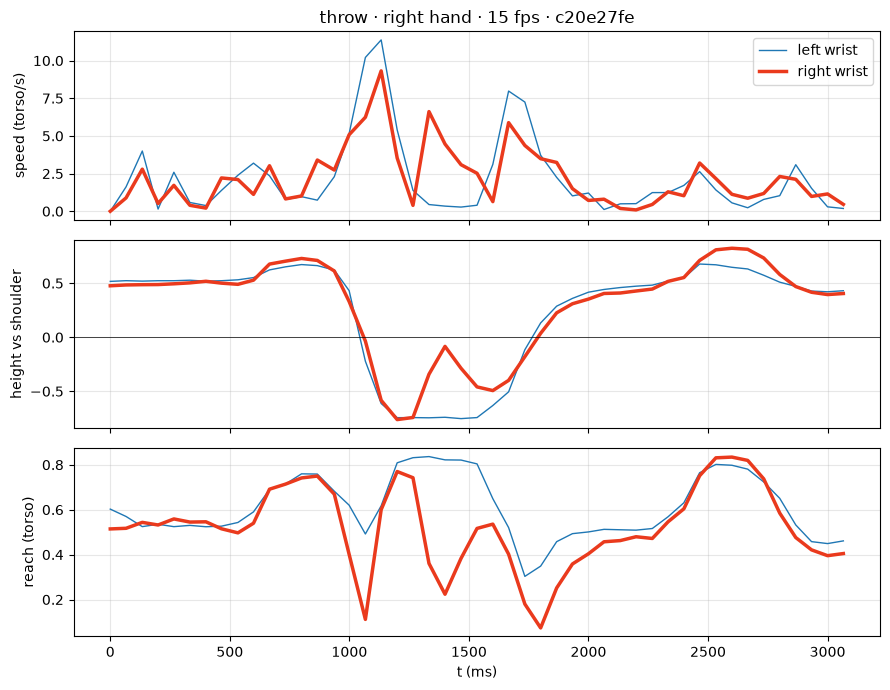

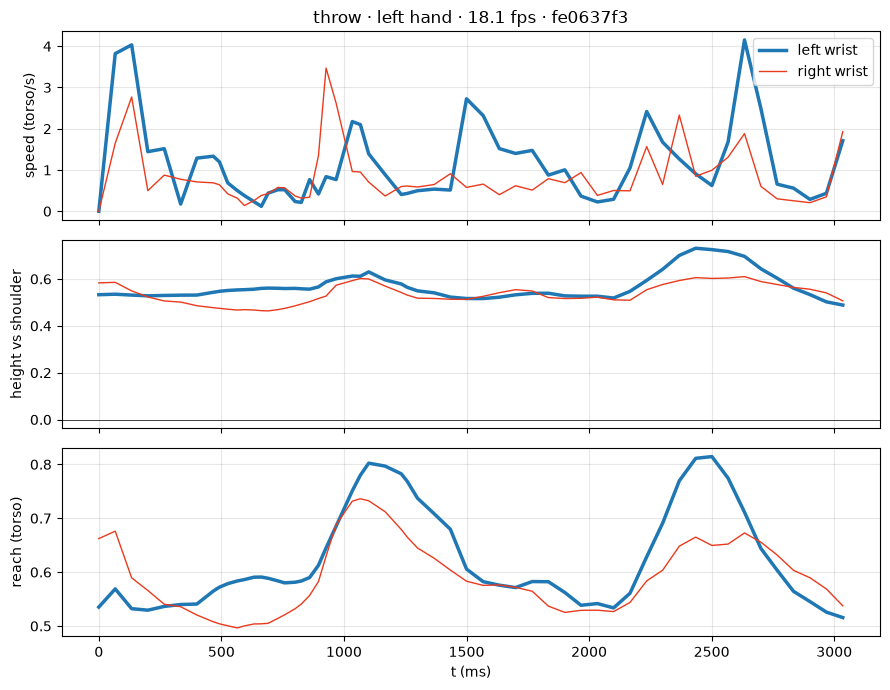

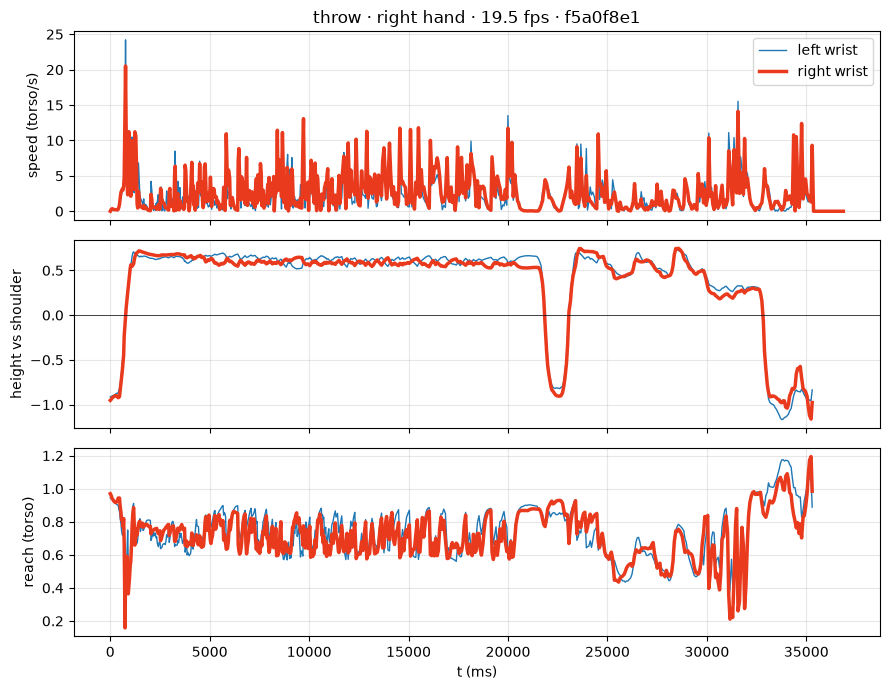

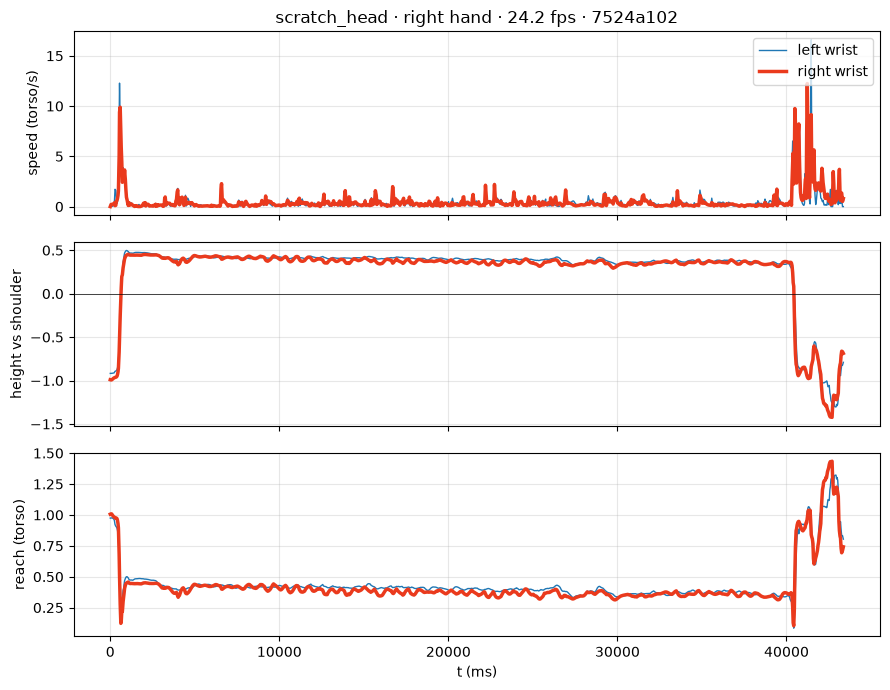

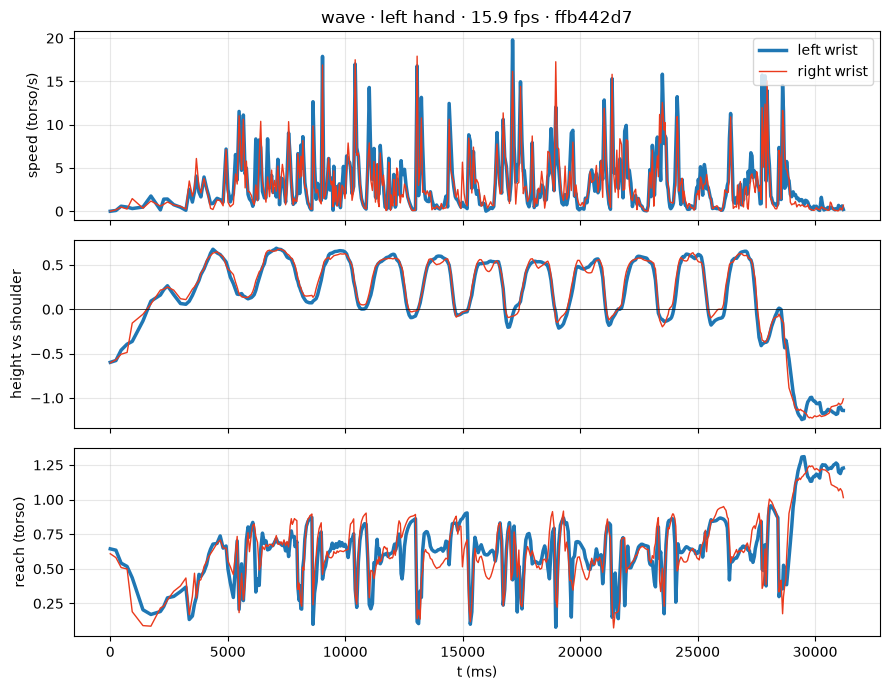

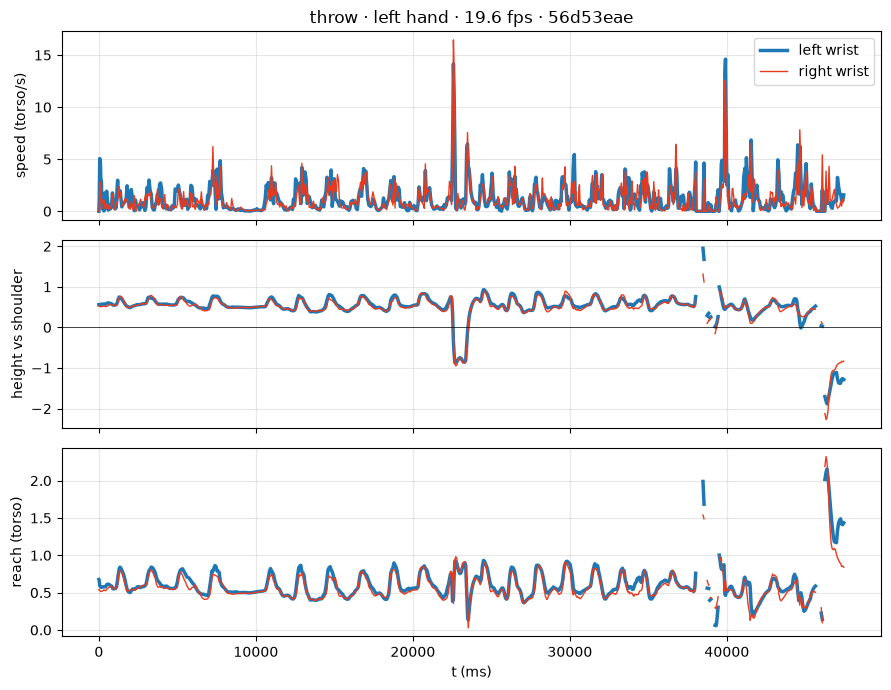

In [4]:
from airhoops_lab.plots import plot_clip
for c in clips:
    plot_clip(c)
    plt.tight_layout(); plt.show()